# 03 — Clustering Kabupaten (v3)

**Pertanyaan:** *kabupaten/kota mana yang mirip dalam skala dan karakter budidaya perikanannya?*

Dipertahankan dari v2: unit = kabupaten, skala log + standardisasi, evaluasi di ruang fitur penuh, k dipilih dengan aturan ukuran-min + stabilitas bootstrap, segmen khusus eksplisit.

**Baru di v3**
* **Set fitur dipilih otomatis** oleh aturan (bukan "B dipilih" yang ditulis tangan) dan **luas lahan ikut diuji** sebagai fitur (Set D) bila lolos `feature_registry`.
* Semua ambang mengikuti jumlah kabupaten (`MIN_SIZE`), bukan angka 5/37 yang ditulis keras.
* Label klaster memakai ambang **relatif** (terhadap median data), jadi tidak basi saat harga/produksi naik; label ganda diberi akhiran `(K#)` — tidak lagi `assert`.
* Keluaran dibuat **persis sesuai kolom yang dibaca dashboard** (`produksi_ton, rtp, pembudidaya, luas_lahan_ha, total_pembesaran` per kab-tahun).

In [1]:
import os, warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, json
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score, silhouette_samples

PROC = Path('../data/processed'); REP = Path('../output/reports'); FIG = Path('../output/figures'); MODEL = Path('../output/models')
for d in (REP, FIG, MODEL): d.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid'); pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
RS = 42
FAST = os.environ.get('PIPE_FAST') == '1'                          # mode cepat (uji / unggah dari dashboard): replikasi lebih sedikit
N_INIT_EVAL, N_BOOT, N_INIT_FINAL = (10, 20, 50) if FAST else (30, 60, 300)

F = pd.read_parquet(PROC / 'features_kab.parquet'); panel = pd.read_parquet(PROC / 'panel_kab_tahun.parquet'); reg = pd.read_csv(REP / 'feature_registry.csv').set_index('fitur')
usable = lambda f: bool(reg.loc[f, 'usable_cluster']) if f in reg.index else False
print('features_kab:', F.shape, '| kolom bernilai kosong:', {c: int(v) for c, v in F.isna().sum().items() if v})
CORE = ['l_produksi', 'l_pembudidaya', 'l_harga', 'shannon']
TIDAK_DIKLASTER = F[F[CORE].isna().any(axis=1)].kabupaten.tolist()      # data inti belum lengkap (mis. kabupaten baru tanpa data pembudidaya)
if TIDAK_DIKLASTER: print('Belum diklaster (data inti belum lengkap):', TIDAK_DIKLASTER); F = F[~F.kabupaten.isin(TIDAK_DIKLASTER)].reset_index(drop=True)
N = len(F); MIN_SIZE = max(3, int(round(0.13 * N))); print(f'N={N} kabupaten -> ukuran klaster minimum = {MIN_SIZE}')

features_kab: (38, 27) | kolom bernilai kosong: {'luas_lahan_ha': 35, 'l_luas': 35}
N=38 kabupaten -> ukuran klaster minimum = 5


## 1. Segmen khusus (outlier struktural)
Aturan eksplisit (domain + statistik): **habitat laut > 90%** *dan* **harga robust-z < −3,5** (produksi besar tetapi harga/kg sangat rendah, mis. rumput laut).
Memasukkannya ke K-Means hanya menghasilkan klaster beranggota satu. Bila tak ada yang memenuhi, daftar kosong dan langkah ini dilewati.

In [2]:
def robust_z(s):
    med = s.median(); mad = (s - med).abs().median() * 1.4826
    return (s - med) / mad if mad > 0 else s * 0
Fi = F.set_index('kabupaten')
spesialis = Fi.index[(Fi.h_laut.fillna(0) > 0.9) & (robust_z(Fi.l_harga) < -3.5)].tolist()
print('Segmen khusus:', spesialis if spesialis else '(tidak ada)')
if spesialis: print(Fi.loc[spesialis, ['produksi_ton', 'harga_rp_kg', 'h_laut']].round(2))
F_fit = F[~F.kabupaten.isin(spesialis)].reset_index(drop=True)
for c in ['h_kolam', 'h_tambak', 'h_laut', 'l_pembenihan', 'l_ikan_hias']: F_fit[c] = F_fit[c].fillna(F_fit[c].median())     # kab tanpa data jenis valid: median (ditandai hab_imputed)
print('Data untuk clustering:', len(F_fit), 'kabupaten | habitat diimputasi:', int(F_fit.hab_imputed.sum()))

Segmen khusus: ['Sumenep']
           produksi_ton  harga_rp_kg  h_laut
kabupaten                                   
Sumenep       692287.33      4961.11    0.99
Data untuk clustering: 37 kabupaten | habitat diimputasi: 0


## 2. Pemilihan fitur (otomatis)
Syarat: tidak redundan, lengkap, tidak spars. Set yang diuji:
* **A** inti (4) · **B** inti + habitat (6) · **C** B + pembenihan + ikan hias (8, spars) · **D** B + **luas lahan** (7) — hanya bila `luas_lahan_ha` lolos registri.

Aturan memilih set (ditulis sebelum melihat hasil): ambil set dengan silhouette terbaik di antara yang **lolos syarat k** (ukuran ≥ `MIN_SIZE`, stabilitas ARI ≥ 0,70);
bila **B** berada dalam 0,02 dari yang terbaik, tetap pakai **B** (kontinuitas tampilan dashboard).

In [3]:
SETS = {'A': ['l_produksi', 'l_pembudidaya', 'l_harga', 'shannon'],
        'B': ['l_produksi', 'l_pembudidaya', 'l_harga', 'shannon', 'h_kolam', 'h_tambak'],
        'C': ['l_produksi', 'l_pembudidaya', 'l_harga', 'shannon', 'h_kolam', 'h_tambak', 'l_pembenihan', 'l_ikan_hias']}
if usable('luas_lahan_ha') and F_fit.l_luas.notna().mean() >= .8:
    F_fit['l_luas'] = F_fit.l_luas.fillna(F_fit.l_luas.median()); SETS['D'] = SETS['B'] + ['l_luas']
else: print('Set D (luas lahan) tidak diuji: cakupan luas belum memadai.')

def boot_stability(X, k, n=N_BOOT, seed=0):
    base = KMeans(k, n_init=N_INIT_EVAL, random_state=RS).fit(X).labels_; rng = np.random.default_rng(seed); a = []
    for b in range(n):
        idx = rng.choice(len(X), len(X), replace=True); a.append(adjusted_rand_score(base, KMeans(k, n_init=5, random_state=b).fit(X[idx]).predict(X)))
    return float(np.mean(a))

def eval_k(X, ks):
    rows = []
    for k in ks:
        lab = KMeans(k, n_init=N_INIT_EVAL, random_state=RS).fit_predict(X)
        rows.append(dict(k=k, silhouette=silhouette_score(X, lab), davies_bouldin=davies_bouldin_score(X, lab), calinski=calinski_harabasz_score(X, lab), ukuran_min=int(np.bincount(lab).min()), stabilitas_ARI=boot_stability(X, k)))
    return pd.DataFrame(rows)

KS = list(range(2, max(2, min(8, len(F_fit) // MIN_SIZE)) + 1))
ev_all = []
for nm, cols in SETS.items():
    e = eval_k(StandardScaler().fit_transform(F_fit[cols]), KS); e.insert(0, 'set_fitur', nm); e['lolos_syarat'] = (e.ukuran_min >= MIN_SIZE) & (e.stabilitas_ARI >= 0.70); ev_all.append(e)
ev_all = pd.concat(ev_all, ignore_index=True); display(ev_all.round(3))

best_by_set = ev_all[ev_all.lolos_syarat].groupby('set_fitur').silhouette.max()
if best_by_set.empty:
    qc_msg = 'TIDAK ADA set/k yang lolos syarat (data terlalu sedikit/tak stabil) -> pakai Set B, k=2'; print('PERINGATAN:', qc_msg); SET_PILIH = 'B'
else:
    SET_PILIH = 'B' if ('B' in best_by_set.index and best_by_set['B'] >= best_by_set.max() - 0.02) else best_by_set.idxmax()
print(f'Set fitur terpilih: {SET_PILIH}  (silhouette terbaik per set yang lolos: {best_by_set.round(3).to_dict()})')

Set D (luas lahan) tidak diuji: cakupan luas belum memadai.


,set_fitur,k,silhouette,davies_bouldin,calinski,ukuran_min,stabilitas_ARI,lolos_syarat
0,A,2,0.315,1.166,21.346,15,0.701,True
1,A,3,0.343,0.997,22.892,8,0.719,True
2,A,4,0.316,0.992,22.667,8,0.670,False
3,A,5,0.289,0.998,21.112,6,0.616,False
4,A,6,0.295,0.997,21.042,3,0.600,False
5,A,7,0.321,0.863,20.824,3,0.610,False
6,B,2,0.365,1.148,23.539,14,0.797,True
7,B,3,0.328,1.034,22.826,8,0.640,False
8,B,4,0.352,0.990,23.648,6,0.740,True
9,B,5,0.352,0.965,22.050,3,0.705,False


Set fitur terpilih: B  (silhouette terbaik per set yang lolos: {'A': 0.343, 'B': 0.365, 'C': 0.301})


## 3. Memilih k
1. ukuran klaster terkecil ≥ `MIN_SIZE`, 2. stabilitas bootstrap ARI ≥ 0,70, 3. dari yang lolos ambil k **terbesar** dengan silhouette dalam 0,02 dari terbaik.

,set_fitur,k,silhouette,davies_bouldin,calinski,ukuran_min,stabilitas_ARI,lolos_syarat,dipilih
0,B,2,0.365,1.148,23.539,14,0.797,True,False
1,B,3,0.328,1.034,22.826,8,0.640,False,False
2,B,4,0.352,0.990,23.648,6,0.740,True,True
3,B,5,0.352,0.965,22.050,3,0.705,False,False
4,B,6,0.327,0.980,22.154,3,0.757,False,False
5,B,7,0.300,1.026,21.250,3,0.707,False,False


k terpilih = 4


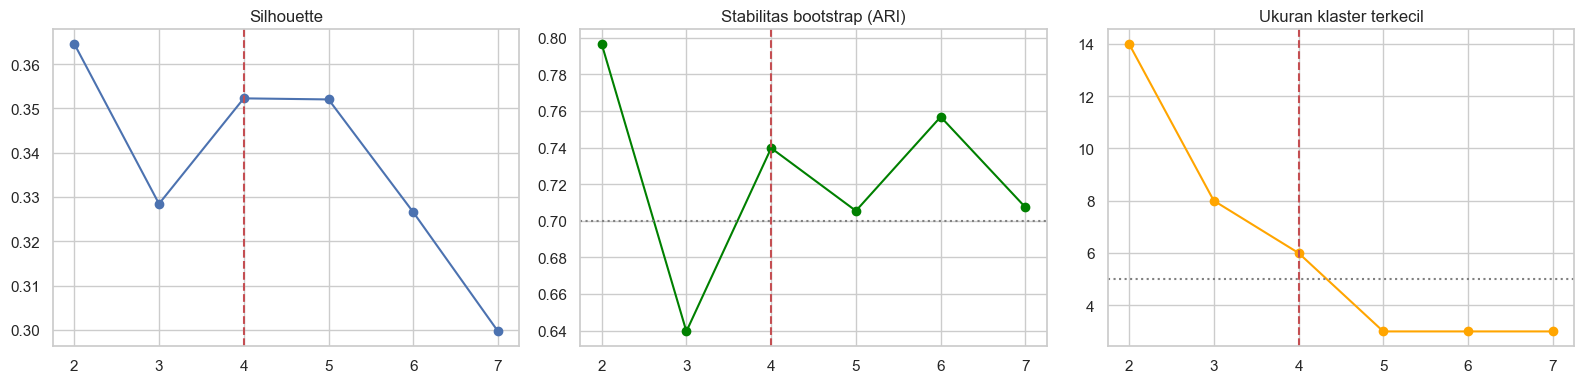

In [4]:
FITUR = SETS[SET_PILIH]; scaler = StandardScaler().fit(F_fit[FITUR]); X = scaler.transform(F_fit[FITUR])
ev = ev_all[ev_all.set_fitur == SET_PILIH].reset_index(drop=True); feas = ev[ev.lolos_syarat]
if feas.empty: k_opt = 2; ev['dipilih'] = ev.k == 2
else:
    best = feas.silhouette.max(); k_opt = int(feas[feas.silhouette >= best - 0.02].k.max()); ev['dipilih'] = ev.k == k_opt
display(ev.round(3)); print(f'k terpilih = {k_opt}')
ev.to_csv(REP / 'clustering_eval.csv', index=False); ev_all.to_csv(REP / 'clustering_eval_semua_set.csv', index=False)   # clustering_eval.csv = format dashboard (kolom k, silhouette) + kolom 'dipilih'

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(ev.k, ev.silhouette, 'o-'); ax[0].axvline(k_opt, color='r', ls='--'); ax[0].set_title('Silhouette')
ax[1].plot(ev.k, ev.stabilitas_ARI, 'o-', color='green'); ax[1].axhline(0.7, color='gray', ls=':'); ax[1].axvline(k_opt, color='r', ls='--'); ax[1].set_title('Stabilitas bootstrap (ARI)')
ax[2].plot(ev.k, ev.ukuran_min, 'o-', color='orange'); ax[2].axhline(MIN_SIZE, color='gray', ls=':'); ax[2].axvline(k_opt, color='r', ls='--'); ax[2].set_title('Ukuran klaster terkecil')
plt.tight_layout(); plt.savefig(FIG / '03_pemilihan_k.png', dpi=110); plt.show()

## 4. Model akhir + pengecekan ketahanan

In [5]:
km = KMeans(k_opt, n_init=N_INIT_FINAL, random_state=RS).fit(X); F_fit['klaster'] = km.labels_
sil = silhouette_score(X, km.labels_); ward = AgglomerativeClustering(k_opt, linkage='ward').fit_predict(X)
print(f'Silhouette = {sil:.3f} | Davies-Bouldin = {davies_bouldin_score(X, km.labels_):.2f} | ARI vs Ward = {adjusted_rand_score(km.labels_, ward):.2f} | stabilitas bootstrap = {boot_stability(X, k_opt):.2f}')
F_fit['silhouette_i'] = silhouette_samples(X, km.labels_); print('Kabupaten dengan silhouette negatif:', int((F_fit.silhouette_i < 0).sum()))

Silhouette = 0.352 | Davies-Bouldin = 0.99 | ARI vs Ward = 0.92 | stabilitas bootstrap = 0.74
Kabupaten dengan silhouette negatif: 0


> **Membaca silhouette.** ~0,3–0,4 = struktur *nyata tetapi tidak tajam*, wajar untuk puluhan kabupaten dengan karakter bertingkat. Silhouette 0,76 di v1 hanyalah artefak klaster beranggota 1.

## 5. Profil & pelabelan (aturan dari data)
Ambang **relatif**: harga "tinggi" = 1,35× median harga kabupaten; "menengah" untuk kolam = produksi di atas median kabupaten.

In [6]:
prof = F_fit.groupby('klaster').agg(n_kab=('kabupaten', 'size'), produksi_ton_median=('produksi_ton', 'median'), pembudidaya_median=('pembudidaya', 'median'),
        harga_rp_kg_median=('harga_rp_kg', 'median'), shannon=('shannon', 'mean'), habitat_kolam=('h_kolam', 'mean'), habitat_tambak=('h_tambak', 'mean'),
        pembenihan_median=('pembenihan_ribu_ekor', 'median'), ikan_hias_median=('ikan_hias_ekor', 'median'), luas_lahan_median=('luas_lahan_ha', 'median'), rtp_median=('rtp', 'median'))
rank_prod = prof.produksi_ton_median.rank(ascending=False, method='first').astype(int)
med_h, med_p = F_fit.harga_rp_kg.median(), F_fit.produksi_ton.median()

def beri_label(r, rk):
    if r.habitat_tambak > 0.5: return 'Tambak Payau – Bernilai Tinggi (Udang)' if r.harga_rp_kg_median > 1.35 * med_h else 'Tambak Payau – Skala Menengah'
    if rk == 1: return 'Skala Besar & Beragam'
    if r.habitat_kolam > 0.7 and r.produksi_ton_median > med_p: return 'Kolam Air Tawar – Skala Menengah'
    return 'Skala Kecil (Perkotaan / Terbatas)'
labels = {k: beri_label(prof.loc[k], rank_prod[k]) for k in prof.index}
dup = pd.Series(labels)[pd.Series(labels).duplicated(keep=False)]
if len(dup): labels = {k: (f'{v} (K{k + 1})' if k in dup.index else v) for k, v in labels.items()}; print('Label ganda -> diberi akhiran (K#):', dup.to_dict())
prof['label'] = pd.Series(labels); F_fit['label'] = F_fit.klaster.map(labels); display(prof.round(2))
for k in prof.index: print(f'K{k} {labels[k]:42s}:', ', '.join(sorted(F_fit[F_fit.klaster == k].kabupaten)))

,n_kab,produksi_ton_median,pembudidaya_median,harga_rp_kg_median,shannon,habitat_kolam,habitat_tambak,pembenihan_median,ikan_hias_median,luas_lahan_median,rtp_median,label
klaster,,,,,,,,,,,,
0,7,9059.22,1854.0,44274.10,0.89,0.17,0.81,16676.0,675.0,148084.00,1803.0,Tambak Payau – Bernilai Tinggi (Udang)
1,15,4902.47,3032.0,19109.65,0.85,0.94,0.03,28242.0,162562.0,142634.25,2356.0,Kolam Air Tawar – Skala Menengah
2,9,235.88,389.0,20864.10,0.81,0.81,0.17,4075.0,11295.0,NaN,235.0,Skala Kecil (Perkotaan / Terbatas)
3,6,51474.70,4669.0,24374.58,1.50,0.35,0.40,199808.5,0.0,NaN,2829.5,Skala Besar & Beragam


K0 Tambak Payau – Bernilai Tinggi (Udang)    : Bangkalan, Banyuwangi, Kota Surabaya, Pacitan, Probolinggo, Sampang, Situbondo
K1 Kolam Air Tawar – Skala Menengah          : Blitar, Bojonegoro, Bondowoso, Jember, Jombang, Kediri, Madiun, Magetan, Malang, Mojokerto, Nganjuk, Ngawi, Ponorogo, Trenggalek, Tulungagung
K2 Skala Kecil (Perkotaan / Terbatas)        : Kota Batu, Kota Blitar, Kota Kediri, Kota Madiun, Kota Malang, Kota Mojokerto, Kota Pasuruan, Kota Probolinggo, Pamekasan
K3 Skala Besar & Beragam                     : Gresik, Lamongan, Lumajang, Pasuruan, Sidoarjo, Tuban


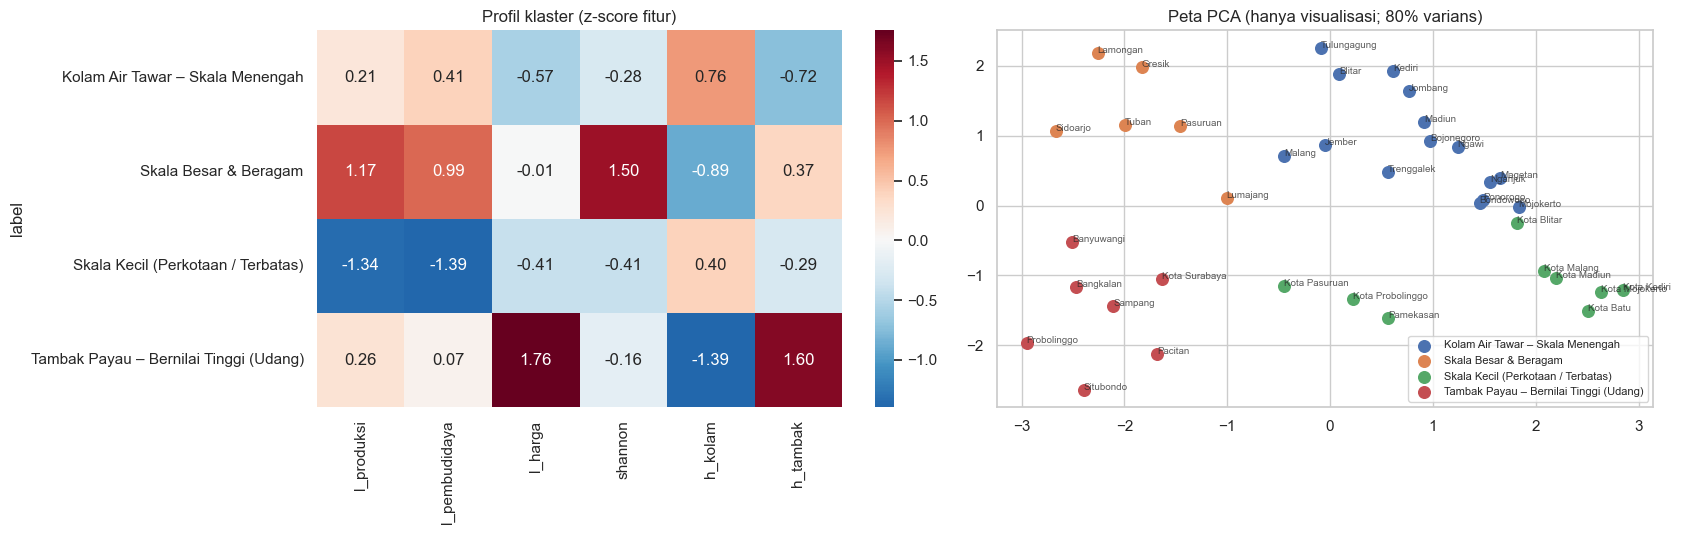

In [7]:
z = pd.DataFrame(X, columns=FITUR); z['label'] = F_fit.label.values; zz = z.groupby('label').mean()
fig, ax = plt.subplots(1, 2, figsize=(17, 5.5)); sns.heatmap(zz, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax[0]); ax[0].set_title('Profil klaster (z-score fitur)')
pc = PCA(2, random_state=RS).fit(X); P = pc.transform(X)
for lab, grp in F_fit.assign(p1=P[:, 0], p2=P[:, 1]).groupby('label'): ax[1].scatter(grp.p1, grp.p2, label=lab, s=70)
for i, r in F_fit.iterrows(): ax[1].annotate(r.kabupaten, (P[i, 0], P[i, 1]), fontsize=7, alpha=.75)
ax[1].set_title(f'Peta PCA (hanya visualisasi; {pc.explained_variance_ratio_.sum():.0%} varians)'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / '03_profil_klaster.png', dpi=110); plt.show()

## 6. Segmen khusus & penempatan per tahun
Segmen khusus = klaster tersendiri. Penempatan per tahun memakai **pusat klaster tetap** (bukan fit ulang tiap tahun), sehingga perpindahan klaster = perubahan nyata fitur kabupaten itu.
Bila fitur suatu kab-tahun kosong, dipakai nilai profil kabupaten itu (`features_kab`); bila tetap kosong, baris dilewati (dashboard menampilkannya sebagai "belum terklasifikasi").

In [8]:
ID_KHUSUS = k_opt; LABEL_KHUSUS = 'Spesialis Rumput Laut (outlier struktural)'
if spesialis:
    d_s = km.transform(scaler.transform(F[F.kabupaten.isin(spesialis)][FITUR])).min(axis=1); d_all = km.transform(X).min(axis=1)
    print(f'Jarak segmen khusus ke pusat terdekat = {d_s.max():.2f} | anggota biasa: median {np.median(d_all):.2f}, maks {d_all.max():.2f} -> {d_s.max() / d_all.max():.1f}x anggota terjauh')
assign = pd.concat([F_fit[['kabupaten', 'klaster', 'label']], pd.DataFrame({'kabupaten': spesialis, 'klaster': ID_KHUSUS, 'label': LABEL_KHUSUS})], ignore_index=True).sort_values('kabupaten').reset_index(drop=True)
assert assign.kabupaten.is_unique
labels_all = {**labels, **({ID_KHUSUS: LABEL_KHUSUS} if spesialis else {})}

py = panel[['kabupaten', 'tahun', 'l_produksi_ton', 'l_pembudidaya', 'l_harga_rp_kg', 'shannon', 'luas_lahan_ha']].rename(columns={'l_produksi_ton': 'l_produksi', 'l_harga_rp_kg': 'l_harga'})
py['l_luas'] = np.log1p(py.pop('luas_lahan_ha'))                       # sama dengan definisi di features_kab (log1p)
py = py.join(F.set_index('kabupaten')[['h_kolam', 'h_tambak']].fillna(F_fit[['h_kolam', 'h_tambak']].median()), on='kabupaten')
fb = F.set_index('kabupaten')[['l_produksi', 'l_pembudidaya', 'l_harga', 'shannon', 'l_luas']]
for c in ['l_produksi', 'l_pembudidaya', 'l_harga', 'shannon', 'l_luas']: py[c] = py[c].fillna(py.kabupaten.map(fb[c]))
py = py.dropna(subset=FITUR).copy()
py['klaster'] = km.predict(scaler.transform(py[FITUR])); py.loc[py.kabupaten.isin(spesialis), 'klaster'] = ID_KHUSUS; py['label'] = py.klaster.map(labels_all)
tab = py.pivot(index='kabupaten', columns='tahun', values='klaster'); stay = (tab.nunique(axis=1) == 1)
print(f'Kabupaten yang selalu di klaster sama: {stay.sum()}/{len(tab)} ({stay.mean():.0%}); kab-tahun tanpa klaster: {len(panel) - len(py)}')
print('Kabupaten yang berpindah:'); display(tab[~stay].astype('Int64'))

Jarak segmen khusus ke pusat terdekat = 5.85 | anggota biasa: median 1.30, maks 2.97 -> 2.0x anggota terjauh
Kabupaten yang selalu di klaster sama: 37/38 (97%); kab-tahun tanpa klaster: 0
Kabupaten yang berpindah:


tahun,2020,2021,2022,2023,2024
kabupaten,,,,,
Mojokerto,1,2,1,1,1


label,Kolam Air Tawar – Skala Menengah,Skala Besar & Beragam,Skala Kecil (Perkotaan / Terbatas),Spesialis Rumput Laut (outlier struktural),Tambak Payau – Bernilai Tinggi (Udang)
tahun,,,,,
2020,15,6,9,1,7
2021,14,6,10,1,7
2022,15,6,9,1,7
2023,15,6,9,1,7
2024,15,6,9,1,7


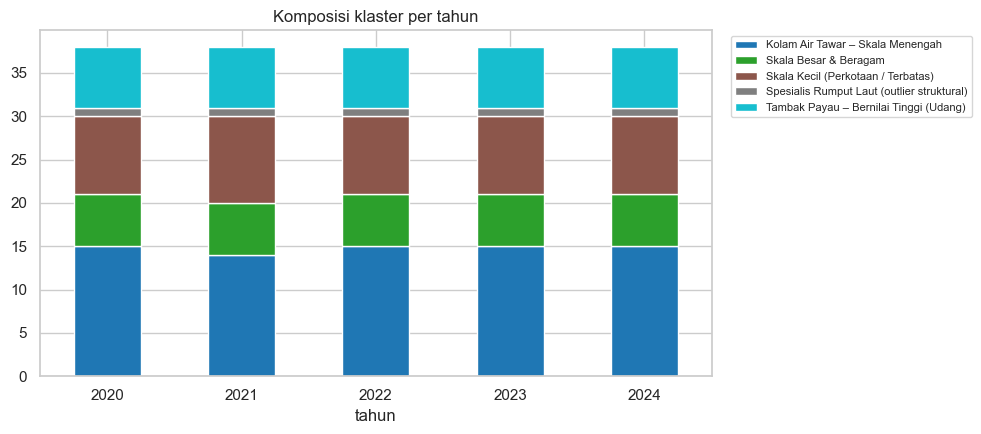

In [9]:
komposisi = py.groupby(['tahun', 'label']).size().unstack(fill_value=0); display(komposisi)
komposisi.plot(kind='bar', stacked=True, figsize=(10, 4.5), colormap='tab10'); plt.title('Komposisi klaster per tahun'); plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8); plt.tight_layout(); plt.savefig(FIG / '03_komposisi_per_tahun.png', dpi=110); plt.show()

## 7. Simpan output (format dashboard)

In [10]:
out = assign.merge(F[['kabupaten'] + [c for c in FITUR if c in F] + ['produksi_ton', 'pembudidaya', 'harga_rp_kg']].drop_duplicates('kabupaten'), on='kabupaten', how='left')
out.to_parquet(REP / 'cluster_assignments.parquet', index=False)
# per kab-tahun: kolom yang dibaca dashboard (FIT_KL). produksi_ton = produksi menurut media (opendata), total_pembesaran = KKP.
cy = py[['kabupaten', 'tahun', 'klaster', 'label']].rename(columns={'label': 'label_klaster'}).merge(
    panel[['kabupaten', 'tahun', 'produksi_media_ton', 'rtp', 'pembudidaya', 'luas_lahan_ha', 'produksi_ton']].rename(columns={'produksi_media_ton': 'produksi_ton', 'produksi_ton': 'total_pembesaran'}), on=['kabupaten', 'tahun'], how='left')
cy['klaster'] = cy.klaster.astype(int); cy.to_parquet(REP / 'cluster_assignments_by_year.parquet', index=False)
prof.reset_index().rename(columns={'klaster': 'id'}).to_csv(REP / 'cluster_profile.csv', index=False)
joblib.dump({'scaler': scaler, 'kmeans': km, 'fitur': FITUR, 'labels': labels_all, 'khusus': spesialis, 'set': SET_PILIH, 'k': k_opt}, MODEL / 'clustering_kmeans.pkl')
json.dump({'set': SET_PILIH, 'k': k_opt, 'silhouette': float(sil), 'fitur': FITUR, 'khusus': spesialis, 'n_klaster_tampil': int(k_opt + (1 if spesialis else 0)), 'min_size': MIN_SIZE, 'tidak_diklaster': TIDAK_DIKLASTER}, open(REP / 'clustering_meta.json', 'w'), indent=1)
print('Tersimpan: cluster_assignments(.parquet, _by_year), cluster_profile.csv, clustering_eval(.csv, _semua_set.csv), models/clustering_kmeans.pkl'); display(cy.head())

Tersimpan: cluster_assignments(.parquet, _by_year), cluster_profile.csv, clustering_eval(.csv, _semua_set.csv), models/clustering_kmeans.pkl


,kabupaten,tahun,klaster,label_klaster,produksi_ton,rtp,pembudidaya,luas_lahan_ha,total_pembesaran
0,Bangkalan,2020,0,Tambak Payau – Bernilai Tinggi (Udang),7060.506,1246.0,1390.0,NaN,7060.62
1,Bangkalan,2021,0,Tambak Payau – Bernilai Tinggi (Udang),7951.914,1040.0,1510.0,NaN,7951.91
2,Bangkalan,2022,0,Tambak Payau – Bernilai Tinggi (Udang),8327.000,1407.0,1380.0,NaN,8244.38
3,Bangkalan,2023,0,Tambak Payau – Bernilai Tinggi (Udang),11564.370,1375.0,1433.0,NaN,9764.37
4,Bangkalan,2024,0,Tambak Payau – Bernilai Tinggi (Udang),NaN,NaN,1424.0,NaN,11966.54


## 8. Ringkasan & batasan
- Semua kabupaten yang punya data ikut diklaster; yang tak punya data valid pada suatu tahun tercatat sebagai "belum terklasifikasi" oleh dashboard (bukan hilang diam-diam).
- Set fitur & k dipilih oleh aturan yang tertulis di atas dan dihitung ulang setiap data bertambah; hasilnya dicatat di `clustering_meta.json`.
- **Batasan:** n kecil; silhouette moderat; habitat dihitung dari tahun yang valid saja; penempatan per tahun memakai pusat klaster tetap.
- **Catatan dashboard:** halaman Tipologi menampilkan "k" dari baris `silhouette` tertinggi di `clustering_eval.csv`. Gunakan kolom `dipilih` (baris k terpilih) bila ingin angka yang persis sama dengan model.